<a href="https://colab.research.google.com/github/ThonggKunn/homework/blob/main/CV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scikit-learn

import pandas as pd
import seaborn as sns
import numpy  as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import matplotlib.ticker as tick
plt.style.use('default')

# Thông tin dataset

Bộ dữ liệu này nằm trong UCI Machine Learning Repository với tên chính thức:
Steel Plates Faults Data Set

Được cung cấp bởi Neuquen Steel S.A. Argentina

Mục tiêu là dự đoán loại lỗi xuất hiện trên tấm thép trong quá trình sản xuất.

Thông tin chung

Số mẫu (rows): 1,941

Số thuộc tính (features): 27

Số nhãn (target classes): 7 loại lỗi

Dạng dữ liệu: numeric (liên tục), không có categorical

Nhiệm vụ: phân loại nhiều lớp (multi-class classification)

# Mount GG Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DRIVE_DATA_PATH = "/content/drive/MyDrive/DataAI/SteelPlateDefectPrediction/faults.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# LOAD DATA

In [ ]:
import os
# Kiểm tra file
if not os.path.exists(DRIVE_DATA_PATH):
    raise FileNotFoundError(f"Error")

df = pd.read_csv(DRIVE_DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (1941, 34)


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,...,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,...,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,...,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,...,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,...,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


# TIỀN XỬ LÝ DỮ LIỆU

In [ ]:
# Kiểm tra giá trị thiếu
print("\nKiểm tra giá trị thiếu:")
print(df.isna().sum())


Kiểm tra giá trị thiếu:
X_Minimum                0
X_Maximum                0
Y_Minimum                0
Y_Maximum                0
Pixels_Areas             0
X_Perimeter              0
Y_Perimeter              0
Sum_of_Luminosity        0
Minimum_of_Luminosity    0
Maximum_of_Luminosity    0
Length_of_Conveyer       0
TypeOfSteel_A300         0
TypeOfSteel_A400         0
Steel_Plate_Thickness    0
Edges_Index              0
Empty_Index              0
Square_Index             0
Outside_X_Index          0
Edges_X_Index            0
Edges_Y_Index            0
Outside_Global_Index     0
LogOfAreas               0
Log_X_Index              0
Log_Y_Index              0
Orientation_Index        0
Luminosity_Index         0
SigmoidOfAreas           0
Pastry                   0
Z_Scratch                0
K_Scatch                 0
Stains                   0
Dirtiness                0
Bumps                    0
Other_Faults             0
dtype: int64


# #Chia X,y

In [ ]:
X = df.iloc[:, :-7]
               # features
y = df.iloc[:, -7:].idxmax(axis=1)
 # label


# #kiểm tra phân bố nhãn

In [ ]:
y.value_counts()


,count
Other_Faults,673
Bumps,402
K_Scatch,391
Z_Scratch,190
Pastry,158
Stains,72
Dirtiness,55


# PHÂN TÍCH DỮ LIỆU

# #Thống kê mô tả


In [ ]:
df.describe()


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
count,1941.000000,1941.000000,1.941000e+03,1.941000e+03,1941.000000,1941.000000,1941.000000,1.941000e+03,1941.000000,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000
mean,571.136012,617.964451,1.650685e+06,1.650739e+06,1893.878413,111.855229,82.965997,2.063121e+05,84.548686,130.193715,...,0.083288,-0.131305,0.585420,0.081401,0.097888,0.201443,0.037094,0.028336,0.207110,0.346728
std,520.690671,497.627410,1.774578e+06,1.774590e+06,5168.459560,301.209187,426.482879,5.122936e+05,32.134276,18.690992,...,0.500868,0.148767,0.339452,0.273521,0.297239,0.401181,0.189042,0.165973,0.405339,0.476051
min,0.000000,4.000000,6.712000e+03,6.724000e+03,2.000000,2.000000,1.000000,2.500000e+02,0.000000,37.000000,...,-0.991000,-0.998900,0.119000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,51.000000,192.000000,4.712530e+05,4.712810e+05,84.000000,15.000000,13.000000,9.522000e+03,63.000000,124.000000,...,-0.333300,-0.195000,0.248200,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,435.000000,467.000000,1.204128e+06,1.204136e+06,174.000000,26.000000,25.000000,1.920200e+04,90.000000,127.000000,...,0.095200,-0.133000,0.506300,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1053.000000,1072.000000,2.183073e+06,2.183084e+06,822.000000,84.000000,83.000000,8.301100e+04,106.000000,140.000000,...,0.511600,-0.066600,0.999800,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
max,1705.000000,1713.000000,1.298766e+07,1.298769e+07,152655.000000,10449.000000,18152.000000,1.159141e+07,203.000000,253.000000,...,0.991700,0.642100,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


# #Phân bố nhãn

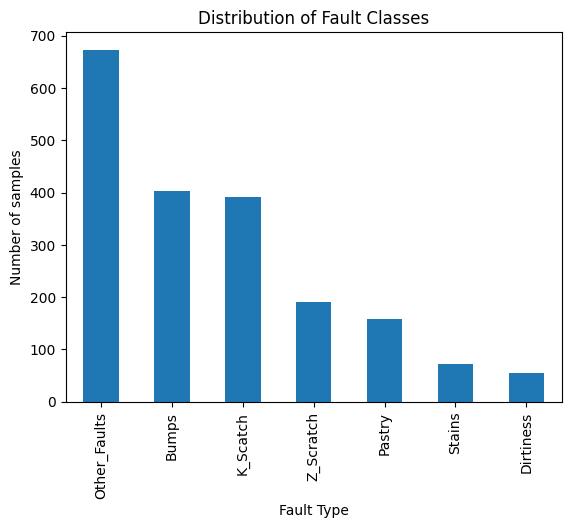

In [ ]:
import matplotlib.pyplot as plt

y.value_counts().plot(kind="bar")
plt.xlabel("Fault Type")
plt.ylabel("Number of samples")
plt.title("Distribution of Fault Classes")
plt.show()


# #Pixel_Area Histogram

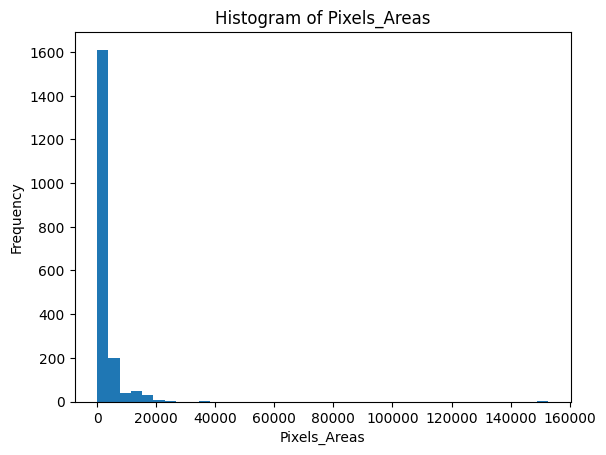

In [ ]:
plt.figure()
plt.hist(df["Pixels_Areas"], bins=40)
plt.xlabel("Pixels_Areas")
plt.ylabel("Frequency")
plt.title("Histogram of Pixels_Areas")
plt.show()


# #Histogram Luminosity

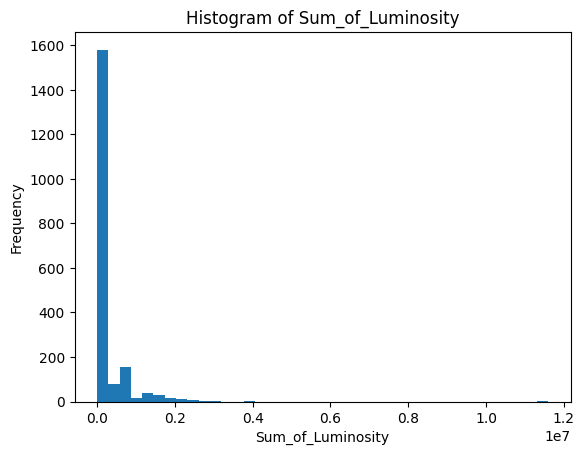

In [ ]:
plt.figure()
plt.hist(df["Sum_of_Luminosity"], bins=40)
plt.xlabel("Sum_of_Luminosity")
plt.ylabel("Frequency")
plt.title("Histogram of Sum_of_Luminosity")
plt.show()


# #Boxplot – phát hiện outlier

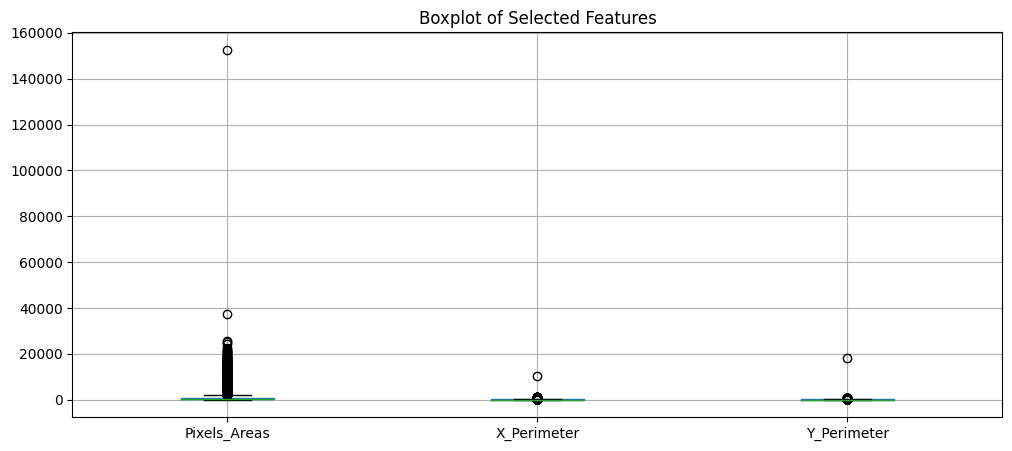

In [ ]:
plt.figure(figsize=(12,5))
df[["Pixels_Areas", "X_Perimeter", "Y_Perimeter"]].boxplot()
plt.title("Boxplot of Selected Features")
plt.show()


# #Ma trận tương quan (heatmap)

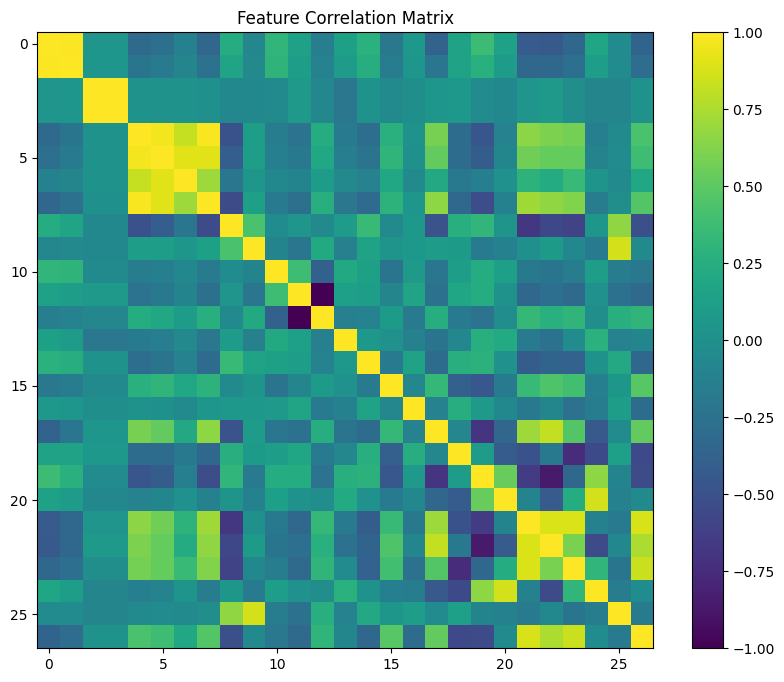

In [ ]:
corr = df.iloc[:, :-7].corr()

plt.figure(figsize=(10,8))
plt.imshow(corr)
plt.colorbar()
plt.title("Feature Correlation Matrix")
plt.show()


# BIỂU ĐỒ HISTOGRAM

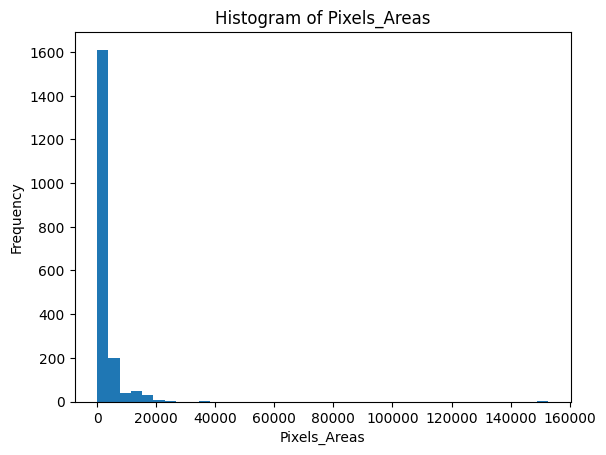

In [ ]:
plt.figure()
plt.hist(df["Pixels_Areas"], bins=40)
plt.xlabel("Pixels_Areas")
plt.ylabel("Frequency")
plt.title("Histogram of Pixels_Areas")
plt.show()


# XÂY DỰNG 3 MÔ HÌNH HỌC MÁY

# Chia Train, Test

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)



# #Chuẩn hoá dữ liệu

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)


# Logistic Regression

In [ ]:
lr_model = LogisticRegression(
    max_iter=500,
    random_state=42
)


# Random Forest

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


# Support Vector Machine (SVM)

In [ ]:
svm_model = SVC(
    kernel="rbf",
    C=1,
    random_state=42
)


# Huấn luyện mô hình

In [ ]:
lr_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)


SVC(C=1, random_state=42)

# Dự đoán trên tập train/test

In [ ]:
y_pred_lr  = lr_model.predict(X_test)
y_pred_rf  = rf_model.predict(X_test)
y_pred_svm = svm_model.predict(X_test)


# Metrics

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# Hàm metrics đánh giá mô hình

In [ ]:
def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    }


# Metrics đánh giá từng mô hình

# Logistic Regression

In [ ]:
metrics_lr = evaluate_model(y_test, y_pred_lr)
metrics_lr


{'Accuracy': 0.7275064267352185,
 'Precision_macro': 0.7612622504383219,
 'Recall_macro': 0.7305280431533564,
 'F1_macro': 0.7417891382899583}

# Random Forest

In [ ]:
metrics_rf = evaluate_model(y_test, y_pred_rf)
metrics_rf


{'Accuracy': 0.8020565552699229,
 'Precision_macro': 0.8386832449838764,
 'Recall_macro': 0.7720969274853985,
 'F1_macro': 0.8012269056740517}

# SVM

In [ ]:
metrics_svm = evaluate_model(y_test, y_pred_svm)
metrics_svm


{'Accuracy': 0.7506426735218509,
 'Precision_macro': 0.8006212672507854,
 'Recall_macro': 0.7389512557432356,
 'F1_macro': 0.7626029076813045}

In [ ]:
print(classification_report(y_test, y_pred_rf))
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_rf


              precision    recall  f1-score   support

       Bumps       0.75      0.72      0.73        81
   Dirtiness       0.89      0.73      0.80        11
    K_Scatch       0.97      0.91      0.94        78
Other_Faults       0.72      0.85      0.78       135
      Pastry       0.64      0.50      0.56        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.97      0.84      0.90        38

    accuracy                           0.80       389
   macro avg       0.84      0.77      0.80       389
weighted avg       0.81      0.80      0.80       389



array([[ 58,   1,   0,  19,   3,   0,   0],
       [  1,   8,   0,   2,   0,   0,   0],
       [  1,   0,  71,   6,   0,   0,   0],
       [ 11,   0,   1, 115,   6,   1,   1],
       [  3,   0,   0,  13,  16,   0,   0],
       [  1,   0,   0,   1,   0,  12,   0],
       [  2,   0,   1,   3,   0,   0,  32]])

# TRỰC QUAN HÓA KẾT QUẢ

In [ ]:
# Dự đoán train & test
y_train_pred_rf = rf_model.predict(X_train)
y_test_pred_rf  = rf_model.predict(X_test)


# Mã hóa nhãn sang số

In [ ]:
label_map = {label: idx for idx, label in enumerate(y.unique())}

y_train_num = y_train.map(label_map)
y_test_num  = y_test.map(label_map)

y_train_pred_num = pd.Series(y_train_pred_rf).map(label_map)
y_test_pred_num  = pd.Series(y_test_pred_rf).map(label_map)


# Biểu đồ hồi quy

# #Train

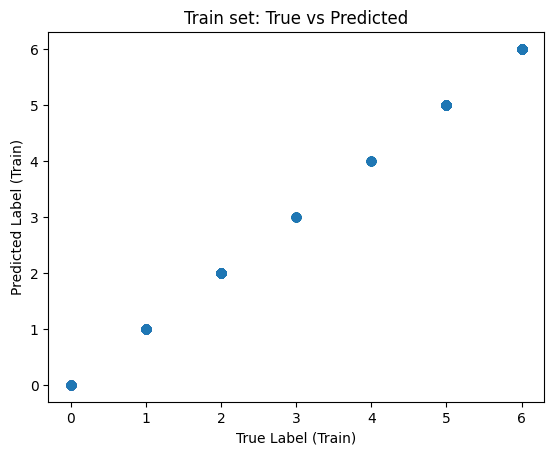

In [ ]:
plt.figure()
plt.scatter(y_train_num, y_train_pred_num, alpha=0.5)
plt.xlabel("True Label (Train)")
plt.ylabel("Predicted Label (Train)")
plt.title("Train set: True vs Predicted")
plt.show()


# #Test

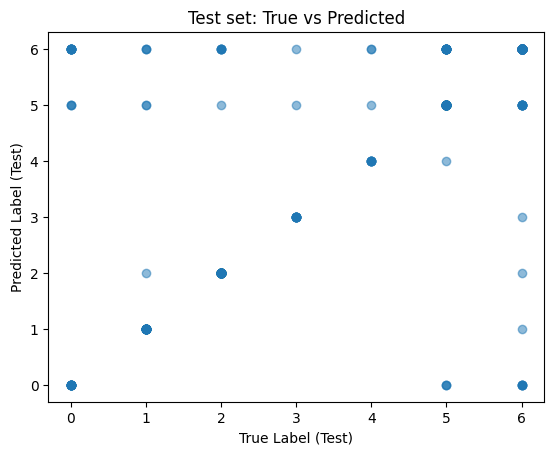

In [ ]:
plt.figure()
plt.scatter(y_test_num, y_test_pred_num, alpha=0.5)
plt.xlabel("True Label (Test)")
plt.ylabel("Predicted Label (Test)")
plt.title("Test set: True vs Predicted")
plt.show()


# #Biểu đồ sai số tuyệt đối

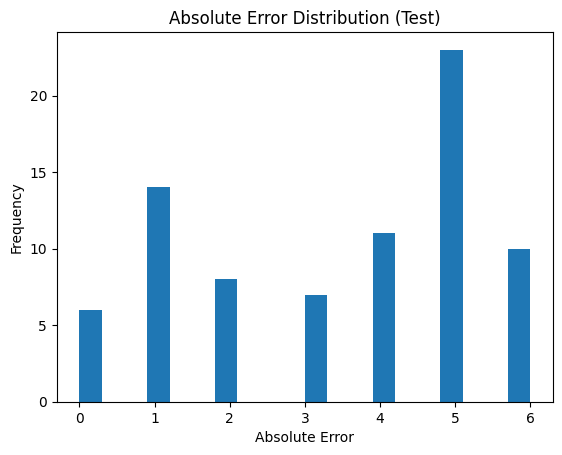

In [ ]:
abs_error = np.abs(y_test_num - y_test_pred_num)

plt.figure()
plt.hist(abs_error, bins=20)
plt.xlabel("Absolute Error")
plt.ylabel("Frequency")
plt.title("Absolute Error Distribution (Test)")
plt.show()


# Biểu đồ sai số tuyệt đối

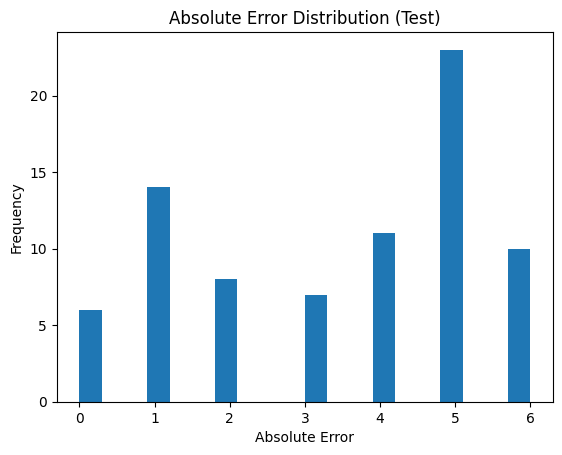

In [ ]:
abs_error = np.abs(y_test_num - y_test_pred_num)

plt.figure()
plt.hist(abs_error, bins=20)
plt.xlabel("Absolute Error")
plt.ylabel("Frequency")
plt.title("Absolute Error Distribution (Test)")
plt.show()


# Biểu đồ sai số tương đối

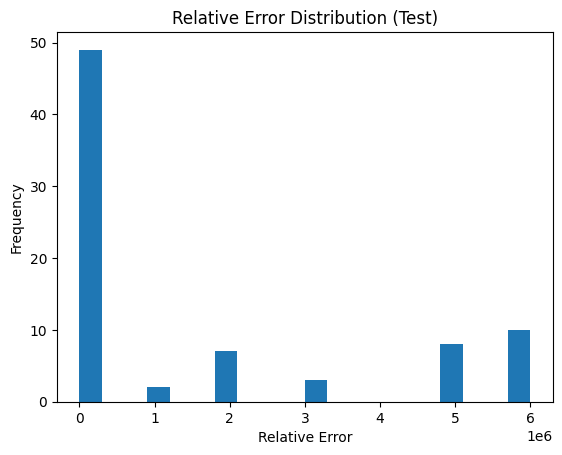

In [ ]:
rel_error = abs_error / (y_test_num + 1e-6)

plt.figure()
plt.hist(rel_error, bins=20)
plt.xlabel("Relative Error")
plt.ylabel("Frequency")
plt.title("Relative Error Distribution (Test)")
plt.show()


# Tổng Hợp


In [ ]:
accuracy_dict = {
    "Logistic Regression": metrics_lr["Accuracy"],
    "Random Forest": metrics_rf["Accuracy"],
    "SVM": metrics_svm["Accuracy"]
}


In [ ]:
for model, acc in accuracy_dict.items():
    print(f"{model}: Accuracy = {acc:.4f}")


Logistic Regression: Accuracy = 0.7275
Random Forest: Accuracy = 0.8021
SVM: Accuracy = 0.7506


In [ ]:
best_model_name = max(accuracy_dict, key=accuracy_dict.get)
best_accuracy = accuracy_dict[best_model_name]

print("\n✅ MÔ HÌNH TỐT NHẤT THEO ACCURACY")
print(f"Model: {best_model_name}")
print(f"Accuracy: {best_accuracy:.4f}")



✅ MÔ HÌNH TỐT NHẤT THEO ACCURACY
Model: Random Forest
Accuracy: 0.8021
